# Stress: the Federal Reserve's scenarios on a fictional bank

Illustrative projections in the shape of the supervisory exercise, not the exercise.

> Harborline Bank is fictional. This is a demonstration on generated data and public datasets; no real customer, account or transaction of any real institution appears here.
>
> Nothing here is a credit decision, a fraud determination, a suspicious activity finding or investment advice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from ledger_core.manifest import Manifest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = Manifest.load(ROOT / "results" / "manifest.json")
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
nii = m.tables["f08.nii_table"]
pl.DataFrame(nii.rows, schema=nii.columns, orient="row")

Parallel shock,Change in net interest income,Share of the last twelve months,From assets,From deposits
i64,f64,f64,f64,f64
-200,-175123.4678,-0.003203,-4.0291e6,3.8540e6
-100,-87561.73388,-0.001601,-2.0145e6,1.9270e6
100,-3490.438028,-0.000064,2014541.8,-2.0180e6
200,-6980.876057,-0.000128,4.0291e6,-4.0361e6


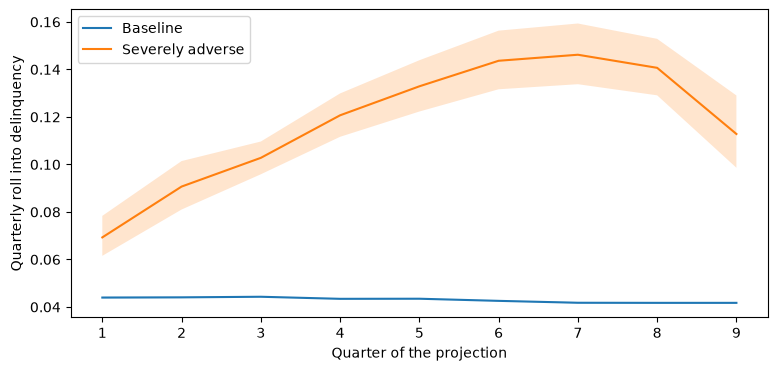

In [3]:
paths = pl.read_parquet(ROOT / "results" / "f08" / "stress_paths.parquet")
fig, ax = plt.subplots()
for name in ("Baseline", "Severely adverse"):
    part = paths.filter(pl.col("scenario") == name).sort("step")
    ax.plot(part["step"], part["roll_rate"], label=name)
    ax.fill_between(part["step"], part["roll_low"], part["roll_high"], alpha=0.2)
ax.set_xlabel("Quarter of the projection")
ax.set_ylabel("Quarterly roll into delinquency")
ax.legend()
plt.show()

In [4]:
print("Severely adverse losses, nine quarters:", m.text("f08.severe_loss"), "(", m.text("f08.severe_loss_low"), "to", m.text("f08.severe_loss_high"), ")")
print("Macro link:", m.text("f08.link_unemployment"), "per point of unemployment; the generator states", m.text("f08.link_stated"))

Severely adverse losses, nine quarters: $59.8M ( $55.9M to $63.9M )
Macro link: 0.215 per point of unemployment; the generator states 0.30
